In [1]:
import pandas as pd
import os

In [2]:
columns = ['Transaction_ID', 'Price', 'Date', 'Postcode', 'Property_Type', 'Old/New', 'Duration', 'PAON', 'SAON', 'Stree', 'Locality', 'Town',
           'District', 'County', 'PPD_Type', 'Record_Status']



In [3]:
dfs = []

for file in os.listdir('data'):
    if file.endswith('.csv'):
        path = 'data/' + file
        df = pd.read_csv(path, names=columns, header=None)
        dfs.append(df)
dt = pd.concat(dfs, ignore_index=True)



In [4]:
dt.shape

(8551939, 16)

In [5]:
dt.head()

,Transaction_ID,Price,Date,Postcode,Property_Type,Old/New,Duration,PAON,SAON,Stree,Locality,Town,District,County,PPD_Type,Record_Status
0,{E073986A-C22E-2134-E053-6C04A8C0233B},450000,2022-02-14 00:00,E1 2FQ,F,Y,L,"JACQUARD POINT, 5",APARTMENT 304,TAPESTRY WAY,NaN,LONDON,TOWER HAMLETS,GREATER LONDON,A,A
1,{E073986A-C232-2134-E053-6C04A8C0233B},272257,2022-02-18 00:00,UB8 2FE,F,Y,L,DOLPHIN BRIDGE HOUSE,FLAT 24,ROCKINGHAM ROAD,NaN,UXBRIDGE,HILLINGDON,GREATER LONDON,A,A
2,{E073986A-C233-2134-E053-6C04A8C0233B},484500,2022-03-01 00:00,E1 2FQ,F,Y,L,"JACQUARD POINT, 5",APARTMENT 504,TAPESTRY WAY,NaN,LONDON,TOWER HAMLETS,GREATER LONDON,A,A
3,{E073986A-C235-2134-E053-6C04A8C0233B},272257,2022-02-18 00:00,UB8 2FE,F,Y,L,DOLPHIN BRIDGE HOUSE,FLAT 37,ROCKINGHAM ROAD,NaN,UXBRIDGE,HILLINGDON,GREATER LONDON,A,A
4,{E073986A-C236-2134-E053-6C04A8C0233B},498750,2022-02-23 00:00,E1 2FQ,F,Y,L,"JACQUARD POINT, 5",APARTMENT 505,TAPESTRY WAY,NaN,LONDON,TOWER HAMLETS,GREATER LONDON,A,A


In [6]:
dt.isnull().sum()

Transaction_ID          0
Price                   0
Date                    0
Postcode            27779
Property_Type           0
Old/New                 0
Duration                0
PAON                    0
SAON              7429514
Stree              153309
Locality          5278257
Town                    0
District                0
County                  0
PPD_Type                0
Record_Status           0
dtype: int64

In [7]:
dt = dt.dropna(subset=['Postcode'])

In [8]:
dt['Date'] = pd.to_datetime(dt['Date'])

In [9]:
dt.dtypes

Transaction_ID               str
Price                      int64
Date              datetime64[us]
Postcode                     str
Property_Type                str
Old/New                      str
Duration                     str
PAON                         str
SAON                         str
Stree                        str
Locality                     str
Town                         str
District                     str
County                       str
PPD_Type                     str
Record_Status                str
dtype: object

In [10]:
dt['Year'] = dt['Date'].dt.year
dt['Month'] = dt['Date'].dt.month

In [11]:
dt.head()

,Transaction_ID,Price,Date,Postcode,Property_Type,Old/New,Duration,PAON,SAON,Stree,Locality,Town,District,County,PPD_Type,Record_Status,Year,Month
0,{E073986A-C22E-2134-E053-6C04A8C0233B},450000,2022-02-14,E1 2FQ,F,Y,L,"JACQUARD POINT, 5",APARTMENT 304,TAPESTRY WAY,NaN,LONDON,TOWER HAMLETS,GREATER LONDON,A,A,2022,2
1,{E073986A-C232-2134-E053-6C04A8C0233B},272257,2022-02-18,UB8 2FE,F,Y,L,DOLPHIN BRIDGE HOUSE,FLAT 24,ROCKINGHAM ROAD,NaN,UXBRIDGE,HILLINGDON,GREATER LONDON,A,A,2022,2
2,{E073986A-C233-2134-E053-6C04A8C0233B},484500,2022-03-01,E1 2FQ,F,Y,L,"JACQUARD POINT, 5",APARTMENT 504,TAPESTRY WAY,NaN,LONDON,TOWER HAMLETS,GREATER LONDON,A,A,2022,3
3,{E073986A-C235-2134-E053-6C04A8C0233B},272257,2022-02-18,UB8 2FE,F,Y,L,DOLPHIN BRIDGE HOUSE,FLAT 37,ROCKINGHAM ROAD,NaN,UXBRIDGE,HILLINGDON,GREATER LONDON,A,A,2022,2
4,{E073986A-C236-2134-E053-6C04A8C0233B},498750,2022-02-23,E1 2FQ,F,Y,L,"JACQUARD POINT, 5",APARTMENT 505,TAPESTRY WAY,NaN,LONDON,TOWER HAMLETS,GREATER LONDON,A,A,2022,2


## Average House Price per Year


In [12]:
avg_price_year = dt.groupby('Year')['Price'].mean()

avg_price_year

Year
2018    347277.029066
2019    352696.411153
2020    373204.848401
2021    387174.466107
2022    411708.066727
2023    404760.110153
2024    398469.126436
2025    391516.372445
2026    360874.217283
Name: Price, dtype: float64

## Average Price by County

In [13]:
avg_price_county = dt.groupby('County')['Price'].mean()
avg_price_county = avg_price_county.sort_values(ascending=False)

In [14]:
avg_price_county

County
GREATER LONDON                811209.058446
WINDSOR AND MAIDENHEAD        715953.730846
SURREY                        649375.393926
BUCKINGHAMSHIRE               573206.425867
HERTFORDSHIRE                 557681.547419
                                  ...      
HARTLEPOOL                    155451.087113
MERTHYR TYDFIL                152317.497757
CITY OF KINGSTON UPON HULL    151015.852827
BLACKPOOL                     145554.928187
BLAENAU GWENT                 141754.579707
Name: Price, Length: 117, dtype: float64

## Average price by property type

In [15]:
avg_price_propert = dt.groupby('Property_Type')['Price'].mean().round(2)

In [16]:
avg_price_propert

Property_Type
D     474480.86
F     317476.02
O    1158366.59
S     294012.26
T     271812.44
Name: Price, dtype: float64

## Number of sales by month.

In [17]:
num_sales_month = dt.groupby('Month')['Price'].count()

In [18]:
num_sales_month

Month
1     610207
2     663369
3     854605
4     586062
5     633442
6     808625
7     703571
8     752789
9     757068
10    719907
11    722322
12    712193
Name: Price, dtype: int64

## London vs Rest


In [19]:
london_avg = dt[dt['County'] == 'GREATER LONDON']['Price'].mean().round(2)

In [20]:
non_london_avg = dt[dt['County'] != 'GREATER LONDON']['Price'].mean().round(2)

In [21]:
london_avg

np.float64(811209.06)

In [22]:
non_london_avg

np.float64(328656.77)

In [23]:
dt.groupby(['County', 'Property_Type'])['Price'].mean().round(2)

County                        Property_Type
BATH AND NORTH EAST SOMERSET  D                 660351.89
                              F                 324798.06
                              O                1252736.17
                              S                 426868.94
                              T                 432087.78
                                                  ...    
YORK                          D                 444611.91
                              F                 228955.93
                              O                1450944.82
                              S                 301454.83
                              T                 303582.62
Name: Price, Length: 585, dtype: float64

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

## Average Price per Year

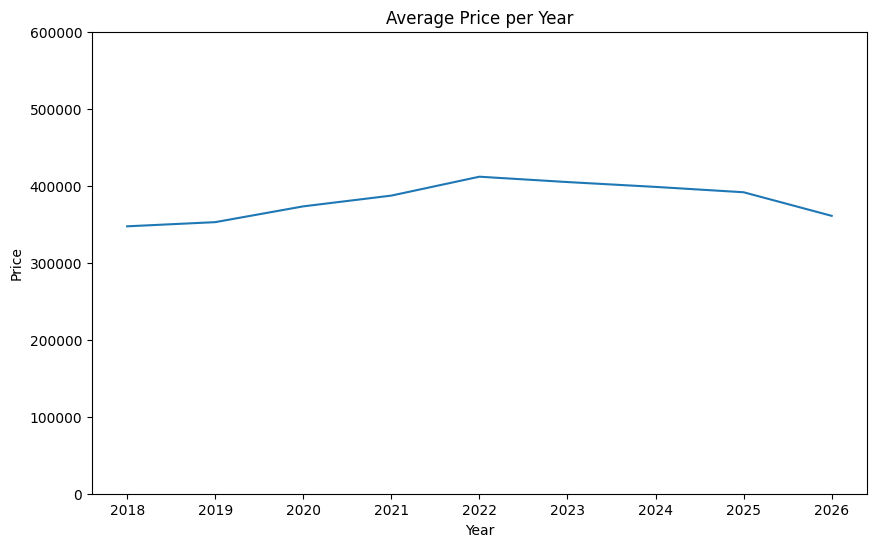

In [25]:
plt.figure(figsize=(10, 6))
plt.ylim(0, 600000)
sns.lineplot(avg_price_year)
plt.title('Average Price per Year')
plt.ylabel('Price')
plt.xlabel('Year')
plt.show()

## Top 10 Most Expensive County

In [26]:
avg_price_country_top_10 = avg_price_county.round(2).sort_values(ascending=False).nlargest(10)

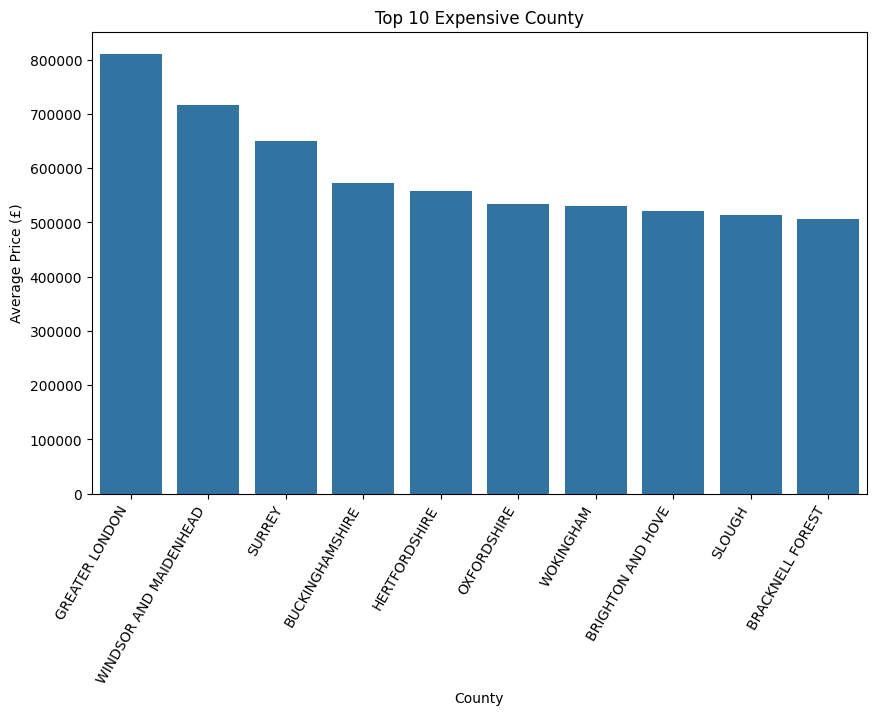

In [27]:
plt.figure(figsize=(10, 6))
sns.barplot(avg_price_country_top_10)
plt.xticks(rotation=60, ha='right')
plt.title('Top 10 Expensive County')
plt.ylabel('Average Price (£)')
plt.show()


## Average Price by Property Type


In [28]:
avg_price_propert

Property_Type
D     474480.86
F     317476.02
O    1158366.59
S     294012.26
T     271812.44
Name: Price, dtype: float64

In [29]:
avg_price_propert = avg_price_propert[avg_price_propert.index != 'O']

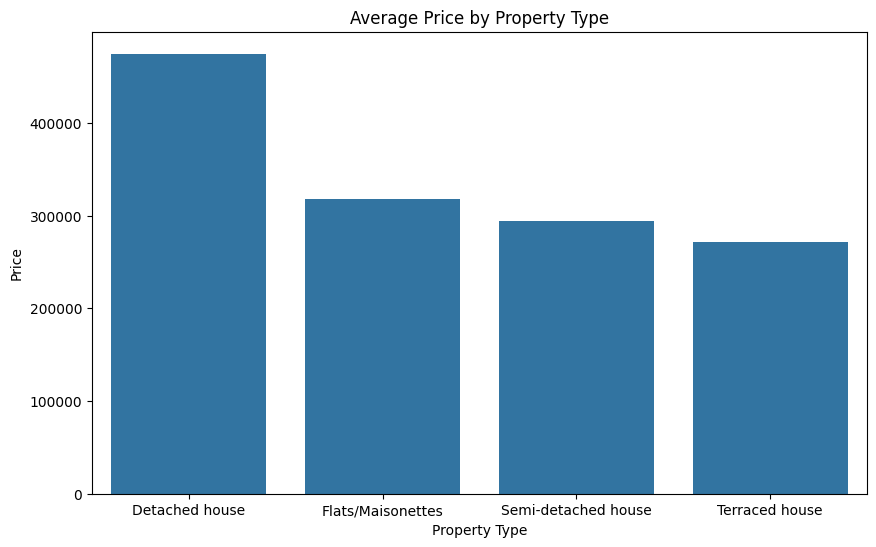

In [30]:
plt.figure(figsize=(10, 6))
plt.ticklabel_format(useOffset=False, style='plain', axis='y')
sns.barplot(avg_price_propert)
plt.title('Average Price by Property Type')
plt.xlabel('Property Type')
plt.ylabel('Price')
plt.xticks(ticks=[0, 1, 2, 3], labels=['Detached house', 'Flats/Maisonettes', 'Semi-detached house', 'Terraced house'])
plt.show()

## Number of Sales Per Month

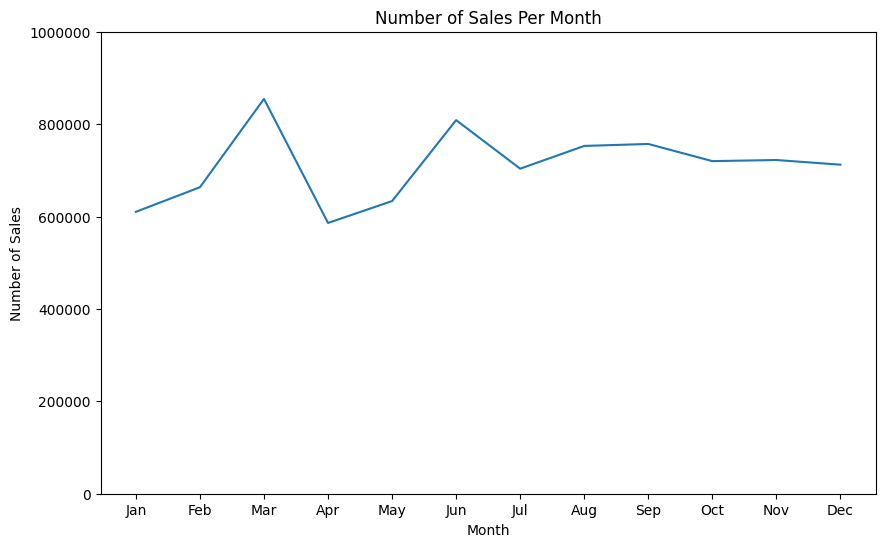

In [51]:
plt.figure(figsize=(10, 6))
sns.lineplot(num_sales_month)
plt.title('Number of Sales Per Month')
plt.ticklabel_format(useOffset=False, style='plain')
plt.ylabel('Number of Sales')
plt.ylim(0, 1000000)
plt.xticks([1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12], ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
plt.show()

## London vs Rest

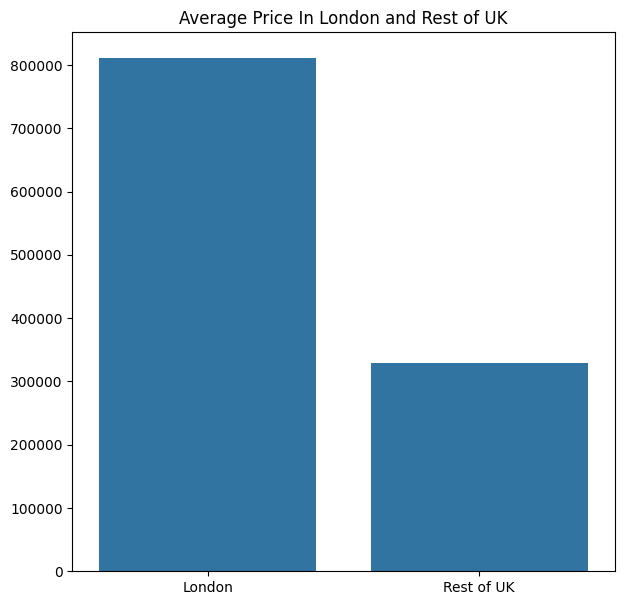

In [63]:
plt.figure(figsize=(7 ,7))
sns.barplot(data = [london_avg, non_london_avg])
plt.title('Average Price In London and Rest of UK')
plt.xticks([0, 1], ['London', 'Rest of UK'])
plt.show()
